In [1]:
#| include: false
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "font.size": 14,
    "axes.labelsize": 15,
    "axes.titlesize": 17,
    "legend.fontsize": 11,
    "lines.linewidth": 2.5,
})

## 1. Question: what interactions/forces act on or between atoms and molecules?

Keywords from the class might include:

**Coulomb · chemical bonds · dispersion · London · van der Waals · H-bonding · hydrophobic · magnetic · gravity · ligand bonds · ionic interactions · polarization · induced dipole · ion–dipole · excluded volume / Pauli repulsion**

### Discuss
Which are fundamental interactions, which are useful molecular interaction models, and which are *consequences* or solvent-mediated effects?

## 2. Order them by interaction strength

### Group task
Put the interactions in approximate order of **energy per mole of interactions** near room temperature.

Use this thermal reference:

$$RT \approx 2.5\ \mathrm{kJ\,mol^{-1}} \qquad (T\approx300\ \mathrm K)$$

Do not worry about exact boundaries: the ranges overlap strongly.

## Approximate energy scales

::: {style="font-size: 72%"}
| Interaction | Rough scale (kJ/mol) | Comment |
|---|---:|---|
| Covalent / strong chemical bond | 100–1000 | Quantum-mechanical bonding |
| Ion–ion | 50–500+ | Strongly environment dependent |
| Metal–ligand / coordination | 50–300 | Very broad range |
| Ion–dipole | 10–100 | Important for ion solvation |
| Hydrogen bond | 5–40 | Directional; environment dependent |
| Dipole–dipole | 1–20 | Orientation dependent |
| Ion–induced dipole | ~1–20 | Polarization |
| London dispersion / vdW | ~0.1–10 per contact | Many contacts add up |
| **Thermal energy, $RT$** | **~2.5** | Useful reference |
| Gravity between molecules | effectively zero | Long-ranged but molecularly negligible |
:::

**Pauli/exchange repulsion** does not have a characteristic small energy: it rises extremely steeply when electron clouds overlap.

## The **thermal energy** is our scale

At 300 K,

$$RT \approx 2.5\ \mathrm{kJ\,mol^{-1}}$$

Instead of only asking whether an interaction is "strong" or "weak", compare its magnitude with thermal energy:

$$\frac{|U|}{RT}\ll 1,\qquad \sim 1,\qquad \gg 1.$$

**Question:** What should thermal motion do to an interaction energy much smaller than $RT$? What if it is much larger?

This comparison will keep returning throughout the course. In statistical thermodynamics it's also common to extress the thermal enerby as $k_BT$.


## 3. Strength is not the whole story: what about range?

### Group task
Rank these by how quickly their potential energy decays with separation $r$:

- ion–ion
- ion–dipole
- dipole–dipole
- ion–induced dipole
- London dispersion

For now, think about **fixed orientations**. We will deal with angular averaging later.

## Pair potentials: distance dependence

| Interaction | Pair potential scaling | Sign / comment |
|---|---:|---|
| Ion–ion | $U\sim 1/r$ | Attractive or repulsive |
| Ion–dipole | $U\sim 1/r^2$ | Orientation dependent |
| Dipole–dipole | $U\sim 1/r^3$ | Orientation dependent |
| Ion–induced dipole | $U=-C_4/r^4$ | **Always attractive** |
| Dipole–induced dipole | $U\sim -1/r^6$ | Attractive after induction |
| London dispersion | $U=-C_6/r^6$ | **Always attractive** |
| Pauli/exchange repulsion | roughly $Ae^{-br}$ | Extremely short-ranged |

The familiar $r^{-12}$ repulsion in Lennard–Jones is a convenient approximation, **not** the fundamental form of exchange repulsion.

---

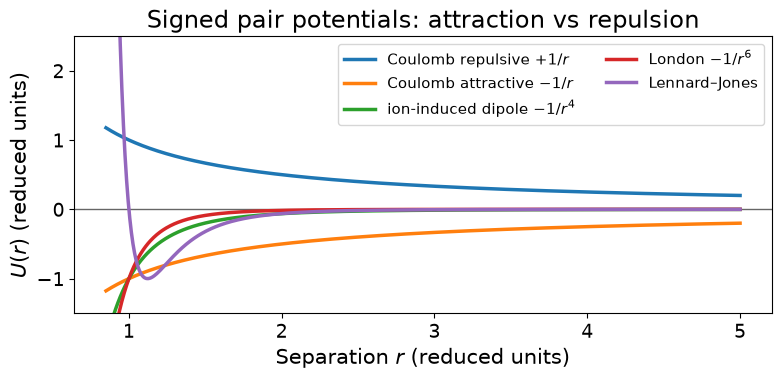

In [2]:
# Illustrative signed potentials: signs and ranges are the point, not absolute magnitudes.
r = np.linspace(0.85, 5.0, 800)

coul_rep = 1/r
ncoul_att = -1/r
ion_ind = -1/r**4
disp = -1/r**6
lj = 4*((1/r)**12 - (1/r)**6)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axhline(0, color='0.4', lw=1)
ax.plot(r, coul_rep, label=r'Coulomb repulsive $+1/r$')
ax.plot(r, ncoul_att, label=r'Coulomb attractive $-1/r$')
ax.plot(r, ion_ind, label=r'ion-induced dipole $-1/r^4$')
ax.plot(r, disp, label=r'London $-1/r^6$')
ax.plot(r, lj, label='Lennard–Jones')
ax.set_ylim(-1.5, 2.5)
ax.set_xlabel(r'Separation $r$ (reduced units)')
ax.set_ylabel(r'$U(r)$ (reduced units)')
ax.set_title('Signed pair potentials: attraction vs repulsion')
ax.legend(ncol=2)
plt.show()

::: {.fragment}
### Important reading of the plot

- $-C_4/r^4$ and $-C_6/r^6$ approach zero **from below**: they are attractive.
- Coulomb can approach zero from above or below depending on the charges.
- A linear signed energy axis is useful for distinguishing attraction and repulsion.

For comparing **range alone**, it is clearer to plot the magnitude $|U|$.
:::

## Potential energy is not force

For pair potentials we conventionally choose

$$U(r\rightarrow\infty)=0.$$

So an attractive interaction has $U<0$ relative to two infinitely separated particles.

The **force** is related to the slope of the potential:

$$F(r)=-\frac{dU(r)}{dr}.$$

## Force at the potential minimum

Therefore:

- a steep potential means a large force,
- an attractive potential need not have a large force everywhere,
- at a minimum of $U(r)$, the slope is zero, so **the net force is zero**.

**Question:** At the Lennard–Jones minimum, is the attraction strongest—or is the force zero?

---

## 4. Why don't atoms collapse together?

London dispersion is attractive. If attraction becomes stronger at short distance, why do two neutral atoms not simply collapse onto one another?

### Discuss
What physical effect is missing from $-C_6/r^6$?

## Excluded volume and Pauli/exchange repulsion

When occupied electron clouds strongly overlap, the energy rises very steeply. A useful conceptual chain is

$$\text{electron-cloud overlap}\rightarrow\text{Pauli/exchange repulsion}\rightarrow\text{steep }U(r)\rightarrow\text{effective excluded volume}.$$

Atoms are therefore **not literally hard spheres**. Their effective size emerges from a steep repulsive potential.

## 5. Lennard–Jones potential

A simple model combines short-range repulsion and London-like attraction:

$$U_{LJ}(r)=4\epsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right].$$

- $\epsilon$: depth of the attractive well
- $\sigma$: distance where $U=0$
- minimum at $r=2^{1/6}\sigma$
- $r^{-12}$: convenient steep repulsion
- $-r^{-6}$: dispersion-like attraction

---

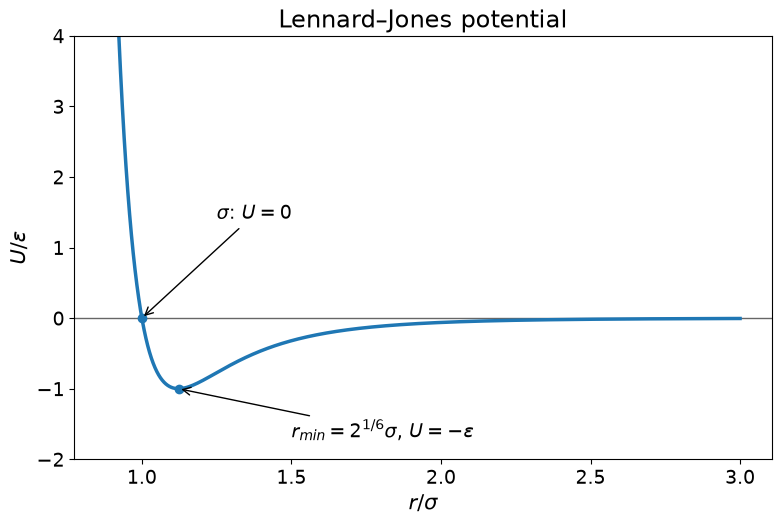

In [3]:
x = np.linspace(0.88, 3.0, 700)
u = 4*(x**-12 - x**-6)
rmin = 2**(1/6)

fig, ax = plt.subplots()
ax.axhline(0, color='0.4', lw=1)
ax.plot(x, u)
ax.scatter([1, rmin], [0, -1], zorder=3)
ax.annotate(r'$\sigma$: $U=0$', (1,0), xytext=(1.25,1.4), arrowprops={'arrowstyle':'->'})
ax.annotate(r'$r_{min}=2^{1/6}\sigma$, $U=-\epsilon$', (rmin,-1), xytext=(1.5,-1.7), arrowprops={'arrowstyle':'->'})
ax.set_ylim(-2, 4)
ax.set_xlabel(r'$r/\sigma$')
ax.set_ylabel(r'$U/\epsilon$')
ax.set_title('Lennard–Jones potential')
plt.show()

## 6. From microscopic interactions to a macroscopic measurement

### Question
Compare the enthalpy of vaporization of:

- methane, CH$_4$
- n-heptane, C$_7$H$_{16}$
- water, H$_2$O$

What interactions hold each liquid together? What do you expect for $\Delta H_{vap}$?

## Approximate values near the normal boiling point

| Substance | Dominant cohesion | $\Delta H_{vap}$ (kJ/mol) | Normal bp |
|---|---|---:|---:|
| CH$_4$ | dispersion; simple LJ-like model useful | ~8.2 | −162 °C |
| n-C$_7$H$_{16}$ | dispersion, many contacts | ~32 | 98 °C |
| H$_2$O | H-bonding + electrostatics + dispersion | ~41 | 100 °C |

## Think

Water and heptane have nearly the same boiling point, but different $\Delta H_{vap}$. What does this tell us?

And why is heptane's cohesive energy so much larger than methane's if both are nonpolar?

## 7. Estimate a Lennard–Jones $\epsilon$ from methane

Suppose methane molecules have roughly $z\approx12$ nearest neighbours and each nearest-neighbour pair contributes approximately $-\epsilon$.

Each pair belongs to **two molecules**, so the cohesive energy per molecule is roughly

$$E_{coh}\approx-\frac{z}{2}\epsilon$$

Using $-E_{coh} = \Delta H_{vap} \approx 8.2$ kJ/mol as a rough cohesive-energy scale:

$$\epsilon\approx\frac{2\Delta H_{vap}}{z}\approx\frac{2(8.2)}{12}\approx1.4\ \mathrm{kJ/mol}.$$

## What assumptions did we make?

- every neighbour has the same separation
- every pair sits near the LJ minimum
- only nearest neighbours matter
- thermal motion is ignored
- $pV$ and other thermodynamic corrections are ignored

Can we replace the crude number **12** by a description of where neighbours actually occur?

## 8. Neighbours in two dimensions

Place one particle at the origin. Consider a thin ring at distance $r$ with thickness $dr$.

For very small $dr$,

$$dA =  \pi \left [ (r+dr)^2 - r^2 \right ] \approx 2\pi r\,dr.$$

If the bulk number density is $\rho$ (particles per unit area), a completely uniform distribution would give

$$dN_{uniform}=\rho\,2\pi r\,dr.$$

But a liquid is **not** uniformly distributed around a particle.

---

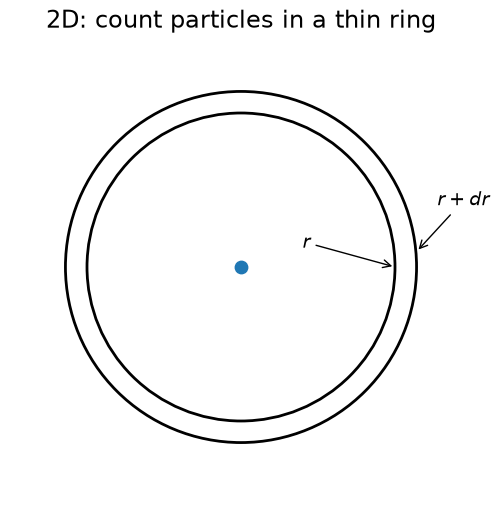

In [13]:
# 2D illustration: central particle and thin annulus
fig, ax = plt.subplots(figsize=(6,6))
r0, dr = 2.0, 0.28
for rad, ls in [(r0, '-'), (r0+dr, '-')]:
    ax.add_patch(plt.Circle((0,0), rad, fill=False, linestyle=ls, linewidth=2))
ax.scatter([0],[0], s=80)
ax.annotate(r'$r$', xy=(r0,0), xytext=(0.8,0.25), arrowprops={'arrowstyle':'->'})
ax.annotate(r'$r+dr$', xy=(r0+dr,0.2), xytext=(2.55,0.8), arrowprops={'arrowstyle':'->'})
ax.set_aspect('equal')
ax.set_xlim(-3,3); ax.set_ylim(-3,3)
ax.set_title('2D: count particles in a thin ring')
ax.axis('off')
plt.show()

## 9. Radial distribution function $g(r)$

Define $g(r)$ as the factor that tells us how the local density differs from the _bulk_ density:

$$\rho(r)=\rho_{bulk}\,g(r).$$

Therefore, in 2D,

$$dN=\rho\,g(r)\,2\pi r\,dr.$$

Interpretation:

- $g(r)=0$: no particles at this distance
- $g(r)=1$: density equals the bulk density
- $g(r)=2$: local density is twice the bulk density

## $g(r)$ is a local-density ratio

An equivalent and very useful definition is

$$\boxed{g(r)=\frac{\rho(r)}{\rho_{\mathrm{bulk}}}}.$$

So $g(r)$ is a **dimensionless local-density ratio**, not itself a number of neighbours. The shell geometry must still be included when counting particles.

## 10. From rings to onion shells: three dimensions

In 3D, replace the thin ring by a thin spherical **onion shell**.

For a thin shell:

$$\text{shell volume}\approx\text{surface area}\times\text{thickness}$$

$$dV=4\pi r^2dr.$$

So the expected number of neighbours in the shell is

$$\boxed{dN=\rho\,g(r)\,4\pi r^2dr}.$$

Notice: **$g(r)$ is not itself the number of neighbours.** The shell volume grows as $r^2$.

---

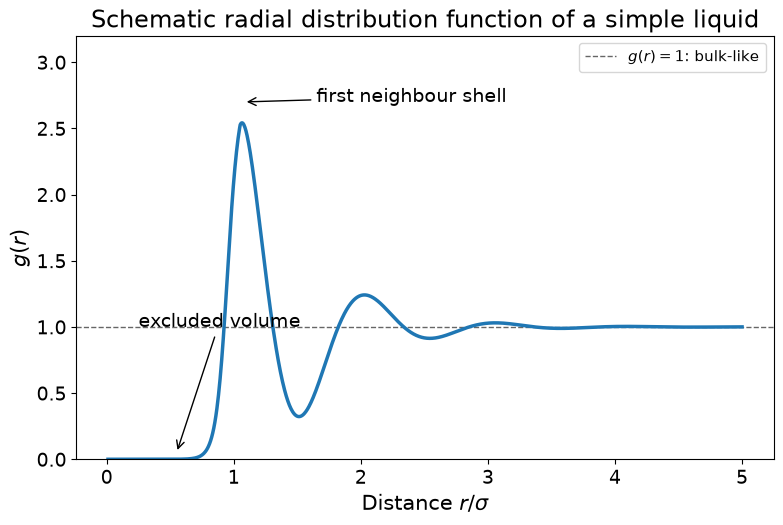

In [6]:
# Schematic RDF for a simple liquid (illustrative, not measured data)
r = np.linspace(0.01, 5.0, 1200)
# excluded core + damped oscillations approaching 1
switch = 1/(1 + np.exp(-(r-0.95)/0.045))
dr = np.maximum(r - 1.05, 0)
g = switch*(1 + 1.8*np.exp(-2.0*dr)*np.cos(6.1*dr))

fig, ax = plt.subplots()
ax.axhline(1, color='0.4', lw=1, ls='--', label=r'$g(r)=1$: bulk-like')
ax.plot(r, g)
ax.set_xlabel(r'Distance $r/\sigma$')
ax.set_ylabel(r'$g(r)$')
ax.set_ylim(0, 3.2)
ax.set_title('Schematic radial distribution function of a simple liquid')
ax.annotate('excluded volume', (0.55,0.05), xytext=(0.25,1.0), arrowprops={'arrowstyle':'->'})
ax.annotate('first neighbour shell', (1.08,2.7), xytext=(1.65,2.7), arrowprops={'arrowstyle':'->'})
ax.legend()
plt.show()

## 11. Coordination number from $g(r)$

The number of neighbours within a distance $R$ is obtained by adding all onion shells:

$$\boxed{N(R)=4\pi\rho\int_0^R g(r)r^2\,dr}.$$

If $R$ is chosen at the first minimum of $g(r)$, this gives a useful definition of the **first-shell coordination number**.

This is the statistical-mechanical replacement for our earlier statement:

> “Assume methane has about 12 neighbours.”

## An assumption: pairwise additivity

For a simple pair-potential model we write the configurational energy as

$$U=\sum_i^{N-1}\sum_{j=i+1}^{N} u(r_{ij}).$$

This assumes the total interaction can be built by adding independent pair interactions.

That is a useful model, but not a fundamental law: polarization, many-body dispersion, and electronic effects can make interactions genuinely many-body.

For the Lennard–Jones liquid we now **adopt the pairwise-additive approximation**.


## 12. From neighbours to the average energy

A neighbour at distance $r$ contributes pair energy $u(r)$.

The shell contains

$$dN=\rho g(r)4\pi r^2dr$$

neighbours, so the interaction energy of the reference molecule with that shell is

$$dU=u(r)\,dN.$$

Add all shells:

$$U_{around\ one}=4\pi\rho\int_0^\infty u(r)g(r)r^2dr.$$

## Correcting for double counting

But every molecular pair is counted twice when we assign this to all molecules. Therefore

$$\boxed{\frac{U}{N}=2\pi\rho\int_0^\infty u(r)g(r)r^2dr}.$$

Conceptually:

$$\boxed{\text{average energy}=\frac12\sum_{shells}(\text{number of neighbours})(\text{pair energy})}$$

## 13. For a Lennard–Jones liquid

Insert

$$u(r)=4\epsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right]$$

into the liquid-energy expression:

$$\boxed{
\frac{U}{N}=2\pi\rho\int_0^\infty
4\epsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right]
g(r)r^2dr
}$$

We have arrived at the mean configurational energy using only:

**pair interaction + geometry + bulk density + liquid structure.**

---

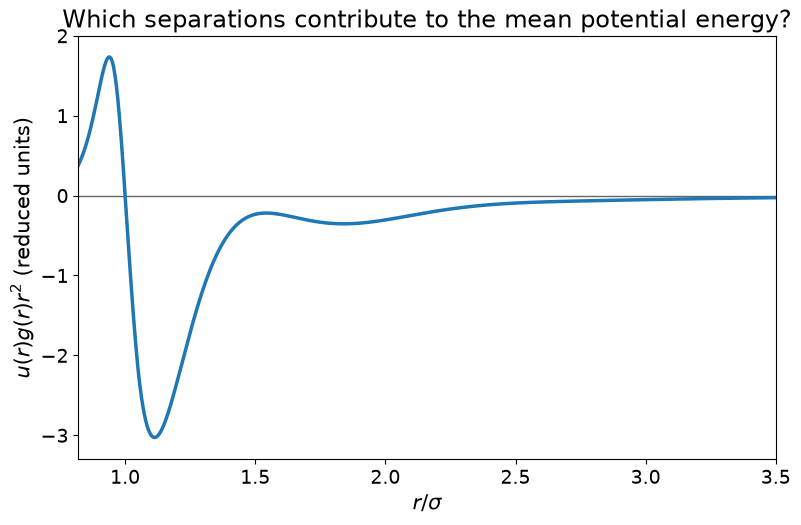

In [12]:
# Illustrative integrand: where does the mean LJ energy come from?
r = np.linspace(0.82, 5.0, 1600)
u = 4*(r**-12-r**-6)
switch = 1/(1 + np.exp(-(r-0.97)/0.03))      # steeper core: g(0.9) ≈ 0.26
dr = np.maximum(r - 1.05, 0)
g = switch*(1 + 1.8*np.exp(-2.0*dr)*np.cos(6.1*dr))   # stays positive, no clip

integrand = u*g*r**2

fig, ax = plt.subplots()
ax.axhline(0, color='0.4', lw=1)
ax.plot(r, integrand)
ax.set_xlim(0.82, 3.5)
ax.set_ylim(-3.3, 2.0)
ax.set_xlabel(r'$r/\sigma$')
ax.set_ylabel(r'$u(r)g(r)r^2$ (reduced units)')
ax.set_title('Which separations contribute to the mean potential energy?')
plt.show()

## Pair potential versus effective/free-energy interaction

Not every "interaction" from our opening poll is a fundamental pair potential.

For example, the **hydrophobic interaction** is largely a solvent-mediated free-energy effect. Bringing two hydrophobic objects together changes the organization and entropy of surrounding water.

So distinguish:

$$\text{microscopic pair potential }u(r)$$

from

$$\text{effective interaction / free-energy change}.$$

This distinction becomes important when we move from isolated pairs to molecules in a solvent.


## 14. Closing questions

1. Why can a weak interaction such as dispersion strongly affect a liquid?
2. Why is **range** as important as the depth of a pair potential?
3. Why does $g(r)\approx0$ at very small $r$?
4. Why does $g(r)\to1$ at large $r$ in a homogeneous liquid?
5. Why is $g(r)$ alone insufficient to count neighbours?
6. Where does the factor $1/2$ in the average pair energy come from?
7. How was our methane estimate $z\epsilon/2$ related to the final integral?

### Next step
For freely rotating polar molecules, orientation changes the effective interactions. In particular, angular averaging changes the simple fixed-orientation distance dependences.

## Preview: interactions, thermal motion, and structure

For an isolated pair in the dilute limit, the Boltzmann factor suggests

$$\boxed{g(r)\approx \exp[-u(r)/(k_BT)]}.$$

This is **not generally true for a dense liquid**, because all the surrounding molecules influence the structure.

But it gives the central idea from statistical thermodynamics:

$$\boxed{u(r)\quad\longrightarrow\quad g(r)\quad\longrightarrow\quad \text{thermodynamic properties}}$$

The pair potential competes with thermal motion; the resulting molecular structure is encoded in $g(r)$; and that structure determines measurable properties.
